# Imports

In [11]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from typing import Tuple, Dict, Any

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
    log_loss,
    mean_squared_error
)
from scipy import stats

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

import optuna


import shap
_HAS_SHAP = True


RANDOM_STATE = 2025

# Helper functions

In [12]:


def load_and_preprocess_data(file_path: str) -> pd.DataFrame:
    df = pd.read_csv(file_path)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df = df.dropna(subset=['TotalCharges'])
    if 'SeniorCitizen' in df.columns:
        df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
    return df


def define_feature_sets(df: pd.DataFrame) -> Tuple[list, list]:
    categorical_columns = [
        'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
        'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
        'PaperlessBilling', 'PaymentMethod'
    ]
    numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
    missing_cat = [c for c in categorical_columns if c not in df.columns]
    missing_num = [c for c in numeric_columns if c not in df.columns]
    if missing_cat or missing_num:
        raise ValueError(f"Colunas ausentes no dataset. Categóricas faltando: {missing_cat}; Numéricas faltando: {missing_num}")
    return categorical_columns, numeric_columns


def create_preprocessor(categorical_columns, numeric_columns) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_columns),
            ('num', StandardScaler(), numeric_columns)
        ]
    )


def calculate_ks_statistic(y_true: np.ndarray, y_proba: np.ndarray):
    class_0_proba = y_proba[y_true == 0]
    class_1_proba = y_proba[y_true == 1]
    ks_stat, p_value = stats.ks_2samp(class_0_proba, class_1_proba)
    return ks_stat, p_value


def compute_metrics(model, X, y, dataset_name='dataset') -> Dict[str, Any]:
    y_probs = model.predict_proba(X)[:, 1]
    y_pred = model.predict(X)

    mse = mean_squared_error(y, y_probs)
    ce = log_loss(y, y_probs)
    cm = confusion_matrix(y, y_pred)
    auroc = roc_auc_score(y, y_probs)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    ks_stat, ks_pvalue = calculate_ks_statistic(y, y_probs)

    print(f"--- Métricas para {dataset_name} ---")
    print(f"MSE: {mse:.4f}")
    print(f"Cross-Entropy (Log Loss): {ce:.4f}")
    print(f"AUROC: {auroc:.4f}")
    print(f"KS Estatística: {ks_stat:.4f} (p-valor: {ks_pvalue:.4f})")
    print(f"Precisão: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print("Matriz de Confusão:")
    print(cm)
    print(classification_report(y, y_pred, digits=4))

    return {
        'mse': mse,
        'cross_entropy': ce,
        'auroc': auroc,
        'ks_stat': ks_stat,
        'ks_p_value': ks_pvalue,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm
    }


def plot_evaluations(model, X, y, dataset_name='Dataset'):
    y_probs = model.predict_proba(X)[:, 1]
    y_pred = model.predict(X)
    cm = confusion_matrix(y, y_pred)

    fpr, tpr, _ = roc_curve(y, y_probs)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'ROC AUC = {roc_auc_score(y, y_probs):.3f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title(f'Curva ROC - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    prec, rec, _ = precision_recall_curve(y, y_probs)
    plt.figure(figsize=(6, 5))
    plt.plot(rec, prec, label='Precision-Recall')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'Curva PR - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    probs_0 = y_probs[y == 0]; probs_1 = y_probs[y == 1]
    all_probs = np.sort(np.concatenate([probs_0, probs_1]))
    cdf_0 = np.searchsorted(probs_0, all_probs, side='right') / len(probs_0)
    cdf_1 = np.searchsorted(probs_1, all_probs, side='right') / len(probs_1)
    ks_statistic = np.max(np.abs(cdf_0 - cdf_1))
    plt.figure(figsize=(6, 5))
    plt.plot(all_probs, cdf_0, label='CDF Classe 0')
    plt.plot(all_probs, cdf_1, label='CDF Classe 1')
    plt.vlines(all_probs[np.argmax(np.abs(cdf_0 - cdf_1))], ymin=min(cdf_0), ymax=max(cdf_1),
               colors='red', linestyles='dashed', label=f'KS = {ks_statistic:.3f}')
    plt.xlabel('Probabilidades'); plt.ylabel('CDF'); plt.title(f'Curva KS - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.ylabel('Real'); plt.xlabel('Predito'); plt.title(f'Matriz de Confusão - {dataset_name}')
    plt.show()


def make_pipeline(preprocessor: ColumnTransformer, trial: optuna.trial.Trial) -> ImbPipeline:
    xgb_n_estimators = trial.suggest_int('xgb_n_estimators', 100, 1000, step=50)
    xgb_max_depth = trial.suggest_int('xgb_max_depth', 3, 12)
    xgb_learning_rate = trial.suggest_float('xgb_learning_rate', 0.01, 0.3, log=True)
    xgb_subsample = trial.suggest_float('xgb_subsample', 0.5, 1.0)
    xgb_colsample_bytree = trial.suggest_float('xgb_colsample_bytree', 0.5, 1.0)
    xgb_gamma = trial.suggest_float('xgb_gamma', 0.0, 5.0)

    classifier = xgb.XGBClassifier(
        n_estimators=xgb_n_estimators,
        max_depth=xgb_max_depth,
        learning_rate=xgb_learning_rate,
        subsample=xgb_subsample,
        colsample_bytree=xgb_colsample_bytree,
        gamma=xgb_gamma,
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    smote_k = trial.suggest_int('smote_k_neighbors', 3, 10)

    pipe = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
        ('classifier', classifier)
    ])
    return pipe


def tune_with_optuna(X_train: pd.DataFrame, y_train: pd.Series,
                     preprocessor: ColumnTransformer,
                     n_trials: int = 40, cv_splits: int = 5,
                     timeout: int | None = None) -> Tuple[ImbPipeline, optuna.Study]:
    def objective(trial: optuna.trial.Trial) -> float:
        pipeline = make_pipeline(preprocessor, trial)
        cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
        scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials, timeout=timeout, show_progress_bar=True)

    print("Melhores parâmetros (Optuna):", study.best_trial.params)
    best_trial = study.best_trial
    best_pipeline = make_pipeline(preprocessor, best_trial)
    best_pipeline.fit(X_train, y_train)

    return best_pipeline, study


def shap_summary_for_model(pipeline: ImbPipeline,
                           X_reference: pd.DataFrame,
                           categorical_columns: list,
                           numeric_columns: list,
                           max_background: int = 800,
                           max_display: int = 20):
    if not _HAS_SHAP:
        print("SHAP não está instalado. Instale com: pip install shap")
        return

    preprocessor: ColumnTransformer = pipeline.named_steps['preprocessor']
    clf = pipeline.named_steps['classifier']

    ohe: OneHotEncoder = preprocessor.named_transformers_['cat']
    ohe_feature_names = list(ohe.get_feature_names_out(categorical_columns))
    feature_names = ohe_feature_names + numeric_columns

    X_proc = preprocessor.transform(X_reference)
    if isinstance(X_proc, np.ndarray):
        X_proc_df = pd.DataFrame(X_proc, columns=feature_names)
    else:
        X_proc_df = pd.DataFrame(X_proc.toarray(), columns=feature_names)

    if len(X_proc_df) > max_background:
        X_bg = X_proc_df.sample(n=max_background, random_state=RANDOM_STATE)
    else:
        X_bg = X_proc_df

    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(X_bg)

    plt.figure()
    try:
        shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values,
                          X_bg, feature_names=feature_names, show=False, max_display=max_display)
    except Exception:
        shap.summary_plot(shap_values, X_bg, feature_names=feature_names, show=False, max_display=max_display)
    plt.title('SHAP Summary (Validação)')
    plt.show()

    plt.figure()
    try:
        shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values,
                          X_bg, feature_names=feature_names, show=False, plot_type='bar', max_display=max_display)
    except Exception:
        shap.summary_plot(shap_values, X_bg, feature_names=feature_names, show=False, plot_type='bar', max_display=max_display)
    plt.title('SHAP Feature Importance (Bar)')
    plt.show()


# Pipeline

In [18]:
df_t = pd.read_csv("../_data/customer_churn_telecom_services.csv")
display(df_t.head)
display(df_t.shape)
display(df_t.columns)

<bound method NDFrame.head of       gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL         

(7043, 20)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [13]:

def main(file_path: str | None = None,
         n_trials: int | None = None,
         cv_splits: int = 5) -> Dict[str, Any]:
    print("INICIANDO PIPELINE COM SMOTE + OPTUNA + SHAP")
    print("=" * 80)

    if file_path is None:
        candidates = [
            '../_data/customer_churn_telecom_services.csv',
            '../../_data/customer_churn_telecom_services.csv',
            '../../../_data/customer_churn_telecom_services.csv',
            'notebooks/_data/customer_churn_telecom_services.csv',
            '_data/customer_churn_telecom_services.csv'
        ]
        for c in candidates:
            if os.path.exists(c):
                file_path = c
                break
        if file_path is None:
            file_path = '../_data/customer_churn_telecom_services.csv'

    df = load_and_preprocess_data(file_path)
    if set(df['Churn'].unique()) == {'Yes', 'No'}:
        y = df['Churn'].map({'No': 0, 'Yes': 1})
    else:
        y = df['Churn']
    categorical_columns, numeric_columns = define_feature_sets(df)
    X = df.drop(columns='Churn')

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
    )
    X_test, X_val, y_test, y_val = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
    )
    print("\nTamanhos dos conjuntos:")
    print(f"Treino: {X_train.shape[0]} | Validação: {X_val.shape[0]} | Teste: {X_test.shape[0]}")
    print(f"Distribuição no treino: {y_train.value_counts().to_dict()}")
    print(f"Distribuição na validação: {y_val.value_counts().to_dict()}")
    print(f"Distribuição no teste: {y_test.value_counts().to_dict()}")

    preprocessor = create_preprocessor(categorical_columns, numeric_columns)

    if n_trials is None:
        n_trials = int(os.getenv("OPTUNA_TRIALS", "40"))

    print(f"\nOtimizando hiperparâmetros com Optuna (n_trials={n_trials}, cv={cv_splits})...")
    best_pipeline, study = tune_with_optuna(
        X_train=X_train, y_train=y_train, preprocessor=preprocessor,
        n_trials=n_trials, cv_splits=cv_splits
    )

    print("\nAvaliação no conjunto de Validação:")
    val_metrics = compute_metrics(best_pipeline, X_val, y_val, dataset_name='Validação')
    plot_evaluations(best_pipeline, X_val, y_val, dataset_name='Validação')

    print("\nAvaliação no conjunto de Teste:")
    test_metrics = compute_metrics(best_pipeline, X_test, y_test, dataset_name='Teste')
    plot_evaluations(best_pipeline, X_test, y_test, dataset_name='Teste')

    print("\nGerando explicações SHAP no conjunto de Validação...")
    shap_summary_for_model(
        best_pipeline, X_val,
        categorical_columns=categorical_columns,
        numeric_columns=numeric_columns,
        max_background=800, max_display=20
    )

    print("\nPIPELINE CONCLUÍDO!")
    return {
        'pipeline': best_pipeline,
        'optuna_study': study,
        'val_metrics': val_metrics,
        'test_metrics': test_metrics,
        'splits': (X_train, y_train, X_val, y_val, X_test, y_test),
        'features': {
            'categorical': categorical_columns,
            'numeric': numeric_columns
        }
    }


[I 2025-08-10 08:31:18,170] A new study created in memory with name: no-name-cf096e85-2335-4c0e-b3a2-8ad39110d692


INICIANDO PIPELINE COM SMOTE + OPTUNA + SHAP

Tamanhos dos conjuntos:
Treino: 4500 | Validação: 1125 | Teste: 1407
Distribuição no treino: {0: 3304, 1: 1196}
Distribuição na validação: {0: 826, 1: 299}
Distribuição no teste: {0: 1033, 1: 374}

Otimizando hiperparâmetros com Optuna (n_trials=40, cv=5)...


Best trial: 0. Best value: 0.833713:   2%|▎         | 1/40 [00:01<00:47,  1.21s/it]

[I 2025-08-10 08:31:19,383] Trial 0 finished with value: 0.8337128511670551 and parameters: {'xgb_n_estimators': 300, 'xgb_max_depth': 5, 'xgb_learning_rate': 0.17723518102572297, 'xgb_subsample': 0.6575684986069653, 'xgb_colsample_bytree': 0.8619065147201614, 'xgb_gamma': 2.732761729601991, 'smote_k_neighbors': 3}. Best is trial 0 with value: 0.8337128511670551.


Best trial: 1. Best value: 0.843617:   5%|▌         | 2/40 [00:02<00:44,  1.17s/it]

...

[I 2025-08-10 08:31:35,531] Trial 37 finished with value: 0.8448345896216483 and parameters: {'xgb_n_estimators': 700, 'xgb_max_depth': 6, 'xgb_learning_rate': 0.025130035017873403, 'xgb_subsample': 0.7738314213571904, 'xgb_colsample_bytree': 0.6735317947006739, 'xgb_gamma': 4.009683648181747, 'smote_k_neighbors': 9}. Best is trial 24 with value: 0.8469051398541272.


Best trial: 24. Best value: 0.846905:  98%|█████████▊| 39/40 [00:17<00:00,  3.12it/s]

[I 2025-08-10 08:31:35,812] Trial 38 finished with value: 0.845520226380939 and parameters: {'xgb_n_estimators': 500, 'xgb_max_depth': 7, 'xgb_learning_rate': 0.03262908866559302, 'xgb_subsample': 0.5984869119279298, 'xgb_colsample_bytree': 0.6158236350135589, 'xgb_gamma': 4.293528603622433, 'smote_k_neighbors': 10}. Best is trial 24 with value: 0.8469051398541272.


Best trial: 24. Best value: 0.846905: 100%|██████████| 40/40 [00:17<00:00,  2.23it/s]


[I 2025-08-10 08:31:36,133] Trial 39 finished with value: 0.8449002869803499 and parameters: {'xgb_n_estimators': 550, 'xgb_max_depth': 4, 'xgb_learning_rate': 0.01286067310942537, 'xgb_subsample': 0.707271476539344, 'xgb_colsample_bytree': 0.5327633981931018, 'xgb_gamma': 3.0177733079918685, 'smote_k_neighbors': 8}. Best is trial 24 with value: 0.8469051398541272.
Melhores parâmetros (Optuna): {'xgb_n_estimators': 450, 'xgb_max_depth': 3, 'xgb_learning_rate': 0.014504721873235078, 'xgb_subsample': 0.750812711827743, 'xgb_colsample_bytree': 0.5937768727136724, 'xgb_gamma': 4.147843827414775, 'smote_k_neighbors': 6}

Avaliação no conjunto de Validação:
--- Métricas para Validação ---
MSE: 0.1436
Cross-Entropy (Log Loss): 0.4352
AUROC: 0.8453
KS Estatística: 0.5416 (p-valor: 0.0000)
Precisão: 0.5758
Recall: 0.6990
F1-Score: 0.6314
Matriz de Confusão:
[[672 154]
 [ 90 209]]
              precision    recall  f1-score   support

           0     0.8819    0.8136    0.8463       826
       

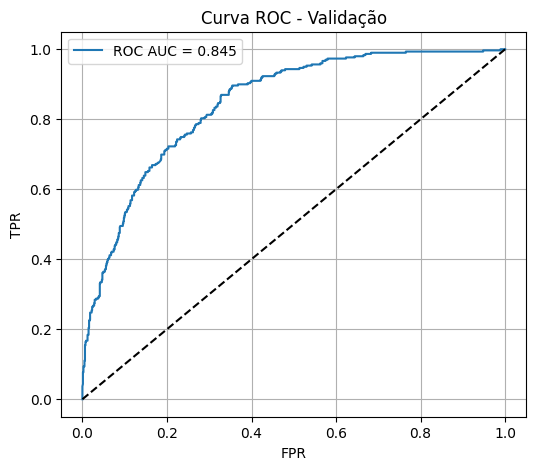

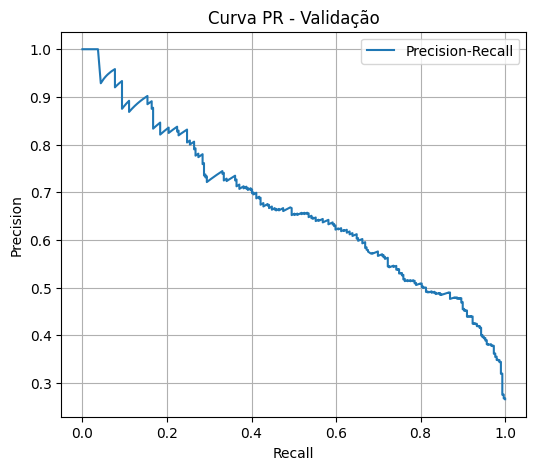

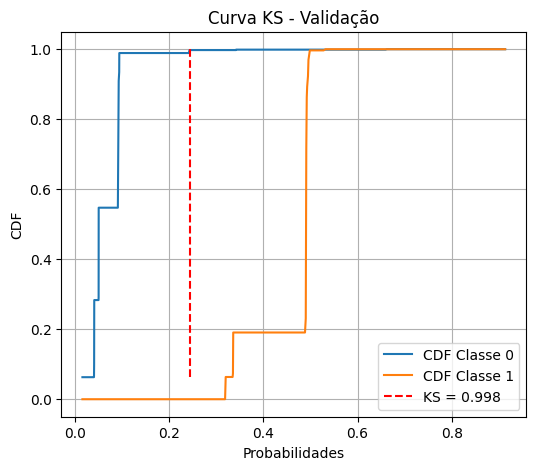

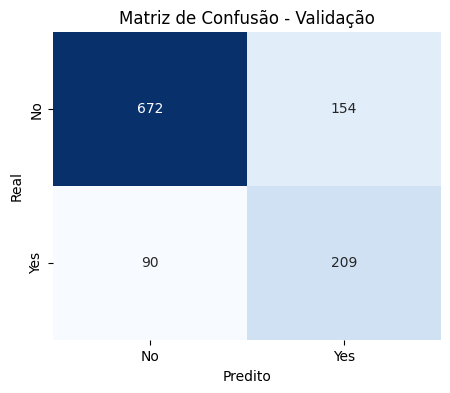


Avaliação no conjunto de Teste:
--- Métricas para Teste ---
MSE: 0.1488
Cross-Entropy (Log Loss): 0.4482
AUROC: 0.8399
KS Estatística: 0.5311 (p-valor: 0.0000)
Precisão: 0.5585
Recall: 0.7273
F1-Score: 0.6318
Matriz de Confusão:
[[818 215]
 [102 272]]
              precision    recall  f1-score   support

           0     0.8891    0.7919    0.8377      1033
           1     0.5585    0.7273    0.6318       374

    accuracy                         0.7747      1407
   macro avg     0.7238    0.7596    0.7348      1407
weighted avg     0.8013    0.7747    0.7830      1407



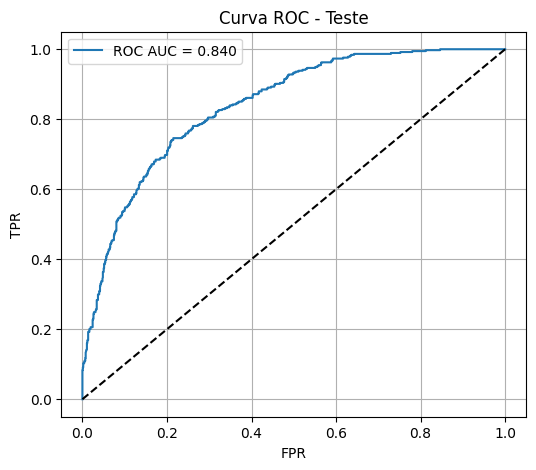

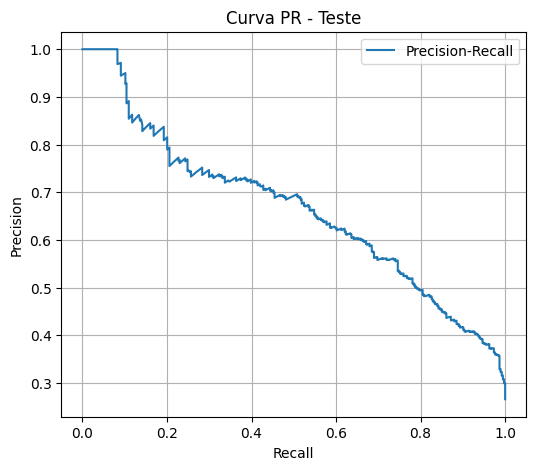

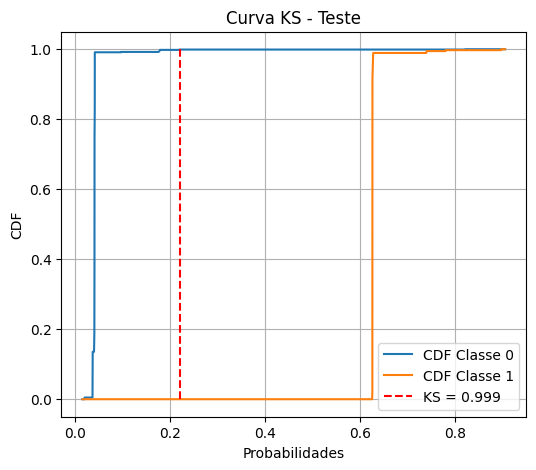

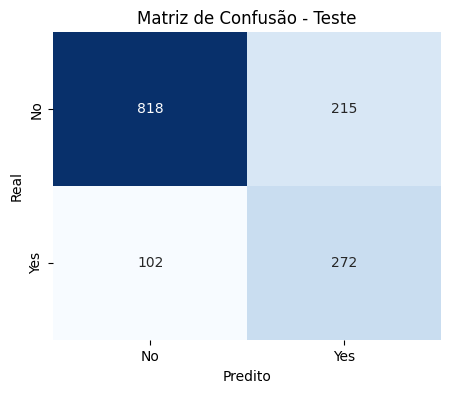


Gerando explicações SHAP no conjunto de Validação...


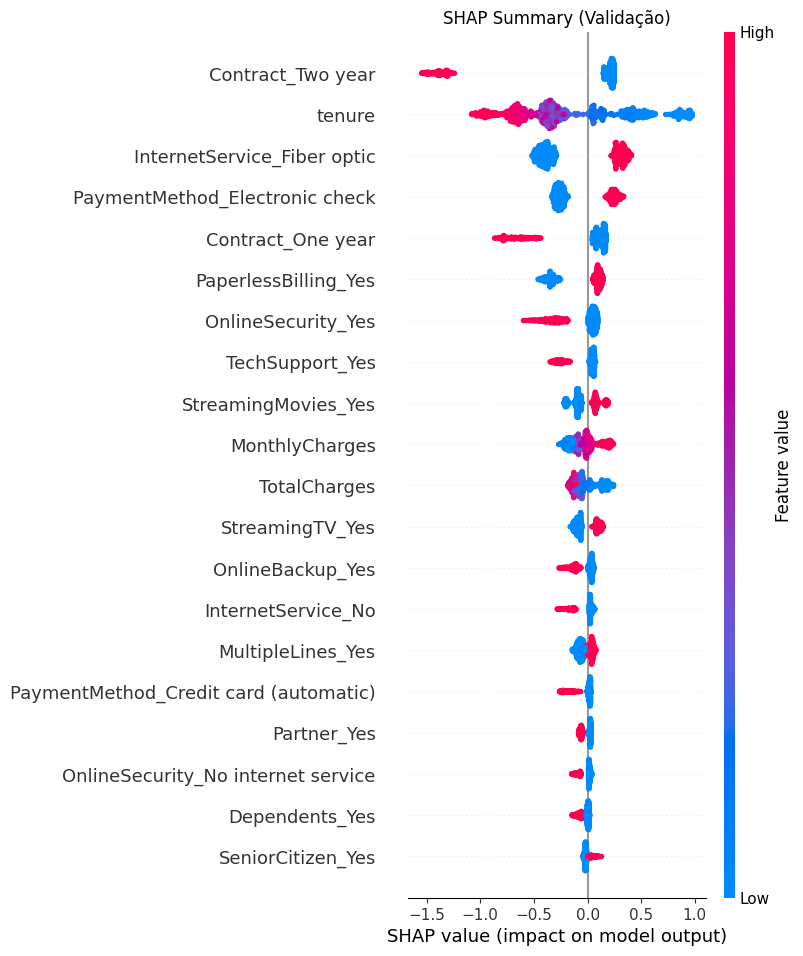

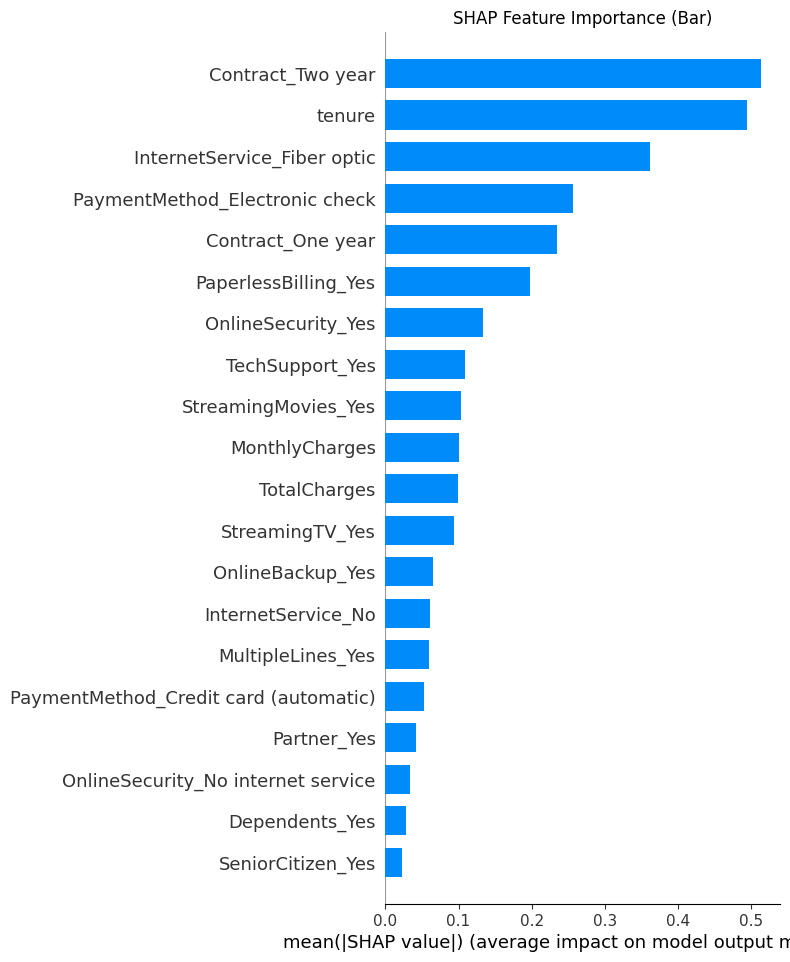


PIPELINE CONCLUÍDO!


In [14]:
if __name__ == "__main__":
    _ = main()